# Stock market analysis using data from the Yahoo-Finance Web API

## Libraries and settings

In [2]:
# Libraries
import os
import ta
import fnmatch
import pandas as pd
import yfinance as yf
from datetime import datetime
import matplotlib.pyplot as plt

# Define settings for graphics
# plt.style.use('dark_background')

# Settings
import warnings
warnings.filterwarnings("ignore")

# Current working directory
print(os.getcwd())

/workspaces/data_ingestion/04_Yahoo_Finance_WebAPI


## Get data
List of stock market symbols: https://finance.yahoo.com/lookup

In [3]:
# Retrieve the Microsoft stock data from Yahoo finance
today = datetime.now().strftime("%Y-%m-%d")
print('Today is:', today)

data = yf.download('MSFT', start="2022-01-01", end=today, progress=False)
data.tail()

Today is: 2026-11-08


Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2026-11-02,507.119995,529.630005,504.959991,524.020020,34743300
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200
2026-11-04,555.799988,559.150024,542.299988,543.700012,50807800
2026-11-05,535.929993,557.619995,532.679993,554.940002,42507900
2026-11-06,530.609985,538.330017,524.469971,525.690002,26938400


## Calculate techniqual indicators

In [4]:
# Function to compute Bollinger Bands
def BBANDS(data, n):
    MA = data.Close.rolling(window=n).mean()
    SD = data.Close.rolling(window=n).std()
    data['MiddleBand'] = MA
    data['UpperBand'] = MA + (2 * SD)
    data['LowerBand'] = MA - (2 * SD)
    return data


# Compute the Bollinger Bands for Google using the 50-day Moving average
BBANDS = BBANDS(data, 50)
BBANDS

Price,Close,High,Low,Open,Volume,MiddleBand,UpperBand,LowerBand
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT,,,
Date,,,,,,,,
2022-01-03,321.856506,324.981327,317.077934,322.433402,28865100,NaN,NaN,NaN
2022-01-04,316.337585,322.289169,313.558885,321.933395,32674300,NaN,NaN,NaN
2022-01-05,304.194000,313.510773,303.809413,313.308840,40054300,NaN,NaN,NaN
2022-01-06,301.790283,306.424638,299.492325,301.088390,39646100,NaN,NaN,NaN
2022-01-07,301.944214,304.309454,298.146343,302.049963,32720000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
2026-11-02,507.119995,529.630005,504.959991,524.020020,34743300,513.388201,546.014581,480.761821
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200,514.061801,545.871074,482.252528


## Plot data and techniqual indicators

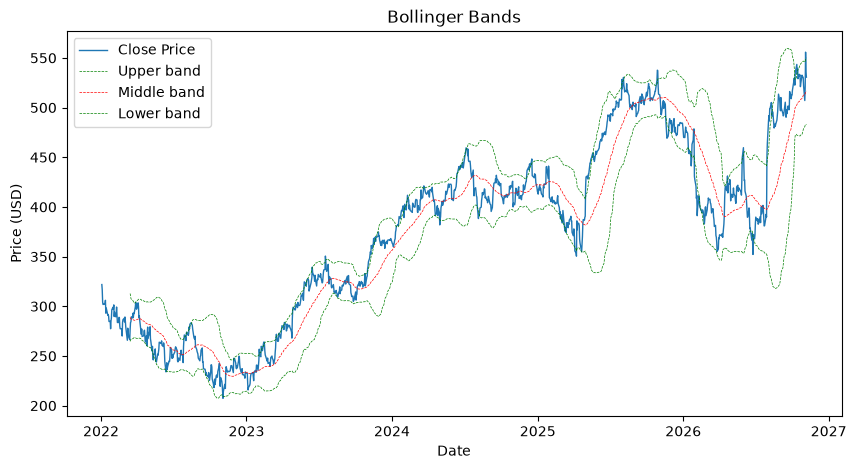

In [5]:
# Create the plot
plt.figure(figsize=(10, 5))

# Set the title and axis labels
plt.title('Bollinger Bands')
plt.xlabel('Date')
plt.ylabel('Price (USD)')

plt.plot(BBANDS.Close, lw=1.0, label='Close Price')
plt.plot(data['UpperBand'], 'g--', lw=0.5, label='Upper band')
plt.plot(data['MiddleBand'], 'r--', lw=0.5, label='Middle band')
plt.plot(data['LowerBand'], 'g--', lw=0.5, label='Lower band')

# Add a legend to the axis
plt.legend()

plt.show()

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [6]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-08 23:43:18
Python Version: 3.12.16
-----------------------------------
